# Restaurant Tips Analysis
Is notebook mein restaurant ke tips ka data dekha hai.
Sawal: kaunsa din, time aur group size tip par asar daalta hai?

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
tips = pd.read_csv(url)

print(tips.head())
print(tips.shape)
print(tips.isnull().sum())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
(244, 7)
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


## Sawal 1: Kaunsa din sabse zyada tip deta hai?

In [4]:
print(tips.groupby('day')['tip'].agg(['mean', 'count']))

          mean  count
day                  
Fri   2.734737     19
Sat   2.993103     87
Sun   3.255132     76
Thur  2.771452     62


Sat aur Sun par zyada tables aaye aur average tip bhi zyada hai (takreeban 3).
Friday ka count sirf 19 hai, is liye us par bharosa kam hai.

## Sawal 2: Lunch ya Dinner, kis mein bill aur tip zyada?

In [5]:
print(tips.groupby('time')[['total_bill', 'tip']].agg(['mean', 'count']))

       total_bill             tip      
             mean count      mean count
time                                   
Dinner  20.797159   176  3.102670   176
Lunch   17.168676    68  2.728088    68


Dinner par bill aur tip dono zyada hain, aur dono groups ka count kaafi hai.

In [6]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
print(tips[['total_bill', 'tip', 'tip_pct']].head())

   total_bill   tip    tip_pct
0       16.99  1.01   5.944673
1       10.34  1.66  16.054159
2       21.01  3.50  16.658734
3       23.68  3.31  13.978041
4       24.59  3.61  14.680765


Sabse zyada tip ki raqam row 4 ki hai (3.61 dollar).
Sabse zyada tip percentage row 2 ki hai (16.66%).

## Lunch ya Dinner, kis mein tip percentage zyada hogi?

In [7]:
print(tips.groupby('time')['tip_pct'].agg(['mean', 'count']))

             mean  count
time                    
Dinner  15.951779    176
Lunch   16.412793     68


Lunch aur Dinner mein tip percentage lagbhag barabar hai (16% ke aas paas).Lunch wale zyada tip dete hain.Dinner ka count 176 hai, is liye uske average par zyada bharosa hai.

## Sawal 3: Smoker aur non-smoker, tip percentage mein farq?

In [8]:
print(tips.groupby('smoker')['tip_pct'].agg(['mean', 'count']))

             mean  count
smoker                  
No      15.932846    151
Yes     16.319604     93


Smoker ka average thora zyada hai (16.3% vs 15.9%), lekin farq bohat chhota hai, to dono lagbhag barabar hain.

## Sawal 4: Group size ka tip percentage par asar?

In [9]:
print(tips.groupby('size')['tip_pct'].agg(['mean', 'count']))

           mean  count
size                  
1     21.729202      4
2     16.571919    156
3     15.215685     38
4     14.594901     37
5     14.149549      5
6     15.622920      4


Group size: Jin sizes ka count theek hai (2, 3, 4), un mein tip percentage girti
jati hai (16.6%, 15.2%, 14.6%), yani bare groups thori kam tip dete hain.
Size 1 ka 21.7% sirf 4 tables par bana hai, is liye us par bharosa nahi.

In [10]:
import matplotlib.pyplot as plt


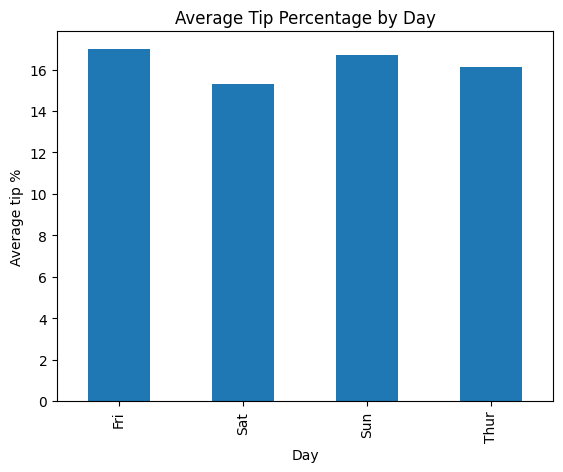

In [15]:
day_avg = tips.groupby('day')['tip_pct'].mean()
day_avg.plot(kind ='bar')
plt.title("Average Tip Percentage by Day")
plt.xlabel("Day")
plt.ylabel("Average tip %")
plt.show()

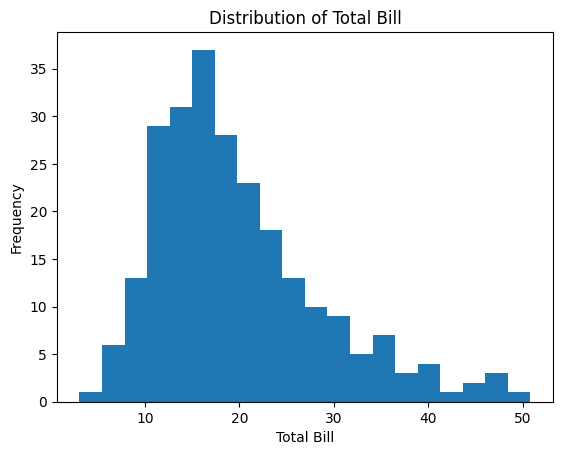

In [16]:
tips['total_bill'].plot(kind='hist', bins=20)
plt.title('Distribution of Total Bill')
plt.xlabel('Total Bill')
plt.show()

## Conclusion

**1. Day:** Sunday has the highest average tip ($3.26), followed by Saturday ($2.99). Thursday ($2.77) and Friday ($2.73) are lower. Weekends also have many more bills (Sat 87, Sun 76), so weekend customers tip more on average. However, Friday has only 19 bills, so its average is less reliable.

**2. Lunch vs Dinner:** Dinner has a higher average bill ($20.80 vs $17.17) and a higher average tip ($3.10 vs $2.73). But in tip percentage, Lunch is slightly ahead (16.4% vs 16.0%). This means dinner tips are larger mainly because the bills are larger, not because customers are more generous. Both groups have enough data (176 dinner bills, 68 lunch bills).

**3. Smoker vs Non-smoker:** Smokers tip 16.3% on average and non-smokers tip 15.9%. The difference is only 0.4 percentage points, so the two groups are practically the same.

**4. Group size:** For the sizes with enough data (2, 3 and 4), tip percentage decreases as the group gets bigger (16.6%, 15.2%, 14.6%). Sizes 1, 5 and 6 have only 4 to 5 bills each, so their averages (for example 21.7% for size 1) should not be trusted.

### Limitations
- Some groups have very little data (Friday, and group sizes 1, 5 and 6), so their averages can change a lot because of a few bills.
- The day analysis uses average tip amount, and bigger bills naturally give bigger tips. Tip percentage would be a fairer comparison.
- This data comes from a single restaurant, so the results may not apply to other restaurants.
- This analysis shows patterns only. It does not prove what causes them.